In [1]:
# ============================================================
# PHASE 07 — FINAL CROSS-MODAL ASD CLASSIFIER
# ============================================================
#
# Goal:
# Genetic + Behavioral + Environmental
#        ↓
# 32-D aligned representations
#        ↓
# Cross-Modal Feature Learning
#        ↓
# Joint Representation
#        ↓
# ASD / NON-ASD Prediction
#
# IMPORTANT:
# Existing frozen modality encoders and 128→32 projections
# will NOT be modified.
#
# First step:
# Audit the existing M3 knowledge-level fusion checkpoint.
# ============================================================

print("PHASE 07 — FINAL CROSS-MODAL ASD CLASSIFIER")
print("Starting checkpoint audit...")

PHASE 07 — FINAL CROSS-MODAL ASD CLASSIFIER
Starting checkpoint audit...


In [2]:
from pathlib import Path
import json
import torch
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(
    r"C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening"
)

OLD_FUSION_DIR = PROJECT_ROOT / "05_multimodal_fusion"

FINAL_DIR = PROJECT_ROOT / "07_final_cross_modal_asd"

MODEL_DIR = FINAL_DIR / "models"
RESULT_DIR = FINAL_DIR / "results"
REPORT_DIR = FINAL_DIR / "reports"
FIGURE_DIR = FINAL_DIR / "figures"

for folder in [
    FINAL_DIR,
    MODEL_DIR,
    RESULT_DIR,
    REPORT_DIR,
    FIGURE_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

M3_CHECKPOINT = OLD_FUSION_DIR / "M3_multimodal_knowledge_fusion.pt"

print("Project:", PROJECT_ROOT)
print("M3 checkpoint:", M3_CHECKPOINT)
print("Exists:", M3_CHECKPOINT.exists())

Project: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening
M3 checkpoint: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\05_multimodal_fusion\M3_multimodal_knowledge_fusion.pt
Exists: True


In [3]:
checkpoint = torch.load(
    M3_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:")
print(type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print(" -", key)
else:
    print("\nCheckpoint is not a dictionary.")

Checkpoint type:
<class 'dict'>

Checkpoint keys:
 - model_state_dict
 - input_dimension
 - hidden_dimension
 - num_modalities
 - modalities
 - best_validation_auc
 - seed


In [4]:
def inspect_object(obj, prefix=""):
    if isinstance(obj, dict):
        for key, value in obj.items():
            print(
                f"{prefix}{key}: "
                f"type={type(value).__name__}, "
                f"shape={getattr(value, 'shape', None)}"
            )

print("CHECKPOINT CONTENTS")
print("=" * 70)

inspect_object(checkpoint)

CHECKPOINT CONTENTS
model_state_dict: type=OrderedDict, shape=None
input_dimension: type=int, shape=None
hidden_dimension: type=int, shape=None
num_modalities: type=int, shape=None
modalities: type=dict, shape=None
best_validation_auc: type=float64, shape=()
seed: type=int, shape=None


In [5]:
m3_report = OLD_FUSION_DIR / "M3_multimodal_knowledge_fusion_report.txt"

print("M3 REPORT")
print("=" * 80)

with open(m3_report, "r", encoding="utf-8") as f:
    report_text = f.read()

print(report_text)

M3 REPORT
ASD MULTIMODAL PROJECT — STEP M3
UNPAIRED MULTIMODAL KNOWLEDGE-LEVEL FUSION

IMPORTANT METHODOLOGICAL NOTE
The three modalities contain different patient populations.
No cross-modal patient matching was performed.
No row-wise concatenation was performed.
The model learns a shared knowledge-level prediction space
using modality-specific representations and modality identity.

DATASET SIZES
Genetic       : 116
Behavioral    : 880
Environmental : 47768

REPRESENTATION DIMENSION
Genetic       : 32-D
Behavioral    : 32-D
Environmental : 32-D

BEST VALIDATION ROC-AUC
0.753685

OVERALL TEST PERFORMANCE
Accuracy: 0.767223
Balanced Accuracy: 0.679861
Precision: 0.130656
Recall: 0.581864
F1: 0.213395
ROC-AUC: 0.762901


GENETIC TEST PERFORMANCE
Accuracy: 0.722222
Balanced Accuracy: 0.500000
Precision: 0.722222
Recall: 1.000000
F1: 0.838710
ROC-AUC: 0.476923

BEHAVIORAL TEST PERFORMANCE
Accuracy: 0.893939
Balanced Accuracy: 0.893939
Precision: 0.825000
Recall: 1.000000
F1: 0.904110
ROC-

In [6]:
config_path = OLD_FUSION_DIR / "M3_2_final_inference_config.json"

print("M3 FINAL INFERENCE CONFIG")
print("=" * 80)

with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

print(json.dumps(config, indent=4))

M3 FINAL INFERENCE CONFIG
{
    "system": "ASD Multimodal Knowledge-Level Evidence Fusion",
    "version": "M3.2",
    "input_dimensions": {
        "genetic": 32,
        "behavioral": 32,
        "environmental": 32
    },
    "evidence_weights": {
        "genetic": 0.3194,
        "behavioral": 0.4002,
        "environmental": 0.2804
    },
    "decision_threshold": 0.5,
    "fusion_method": "weighted probability evidence fusion",
    "patient_matching_training": false,
    "row_wise_training_fusion": false,
    "single_patient_inference": true,
    "genetic_model": "/content/drive/MyDrive/ASD_Multimodal_Project/05_multimodal_fusion/M3_1_genetic_expert.pt",
    "behavioral_model": "/content/drive/MyDrive/ASD_Multimodal_Project/05_multimodal_fusion/M3_1_behavioral_expert.pt",
    "environmental_model": "/content/drive/MyDrive/ASD_Multimodal_Project/05_multimodal_fusion/M3_1_environmental_expert.pt"
}


In [7]:
validation_path = OLD_FUSION_DIR / "M3_3_final_inference_validation_report.txt"

print("M3 VALIDATION REPORT")
print("=" * 80)

with open(validation_path, "r", encoding="utf-8") as f:
    validation_text = f.read()

print(validation_text)

M3 VALIDATION REPORT

ASD MULTIMODAL PROJECT — STEP M3.3
FINAL THREE-EXPERT INFERENCE VALIDATION

SYSTEM

Genetic expert        : LOADED
Behavioral expert     : LOADED
Environmental expert  : LOADED

INPUT STRUCTURE

Genetic input         : 32-D
Behavioral input      : 32-D
Environmental input   : 32-D

EVIDENCE WEIGHTS

Genetic       : 0.319400
Behavioral    : 0.400200
Environmental : 0.280400

Weight sum    : 1.000000

VALIDATION

32-D validation              : PASSED
NaN validation               : PASSED
Inf validation               : PASSED
Probability range            : PASSED
Evidence fusion calculation : PASSED
Multiple sample inference   : PASSED
Determinism                 : PASSED

EXAMPLE INFERENCE

Genetic probability       : 0.431408
Behavioral probability    : 0.520225
Environmental probability : 0.035701

Final ASD probability     : 0.355996

Prediction                : 0
Label                     : NON-ASD

IMPORTANT ARCHITECTURAL NOTE

The original modality datasets co

In [9]:
# PART B — FINAL CROSS-MODAL ASD MODEL

In [11]:
# # ============================================================
# # PART B — FINAL CROSS-MODAL ASD CLASSIFIER
# # ============================================================

# The M3 model was verified as an unpaired multimodal
# knowledge-level fusion baseline.

# It combines modality-specific ASD predictions at the
# knowledge/probability level.

# The final model developed below is different:

# Genetic 32-D
# Behavioral 32-D
# Environmental 32-D
#         ↓
# Cross-Modal Feature Interaction
#         ↓
# Joint Representation
#         ↓
# ASD Classifier
#         ↓
# ASD / NON-ASD

# The existing frozen modality encoders and 128→32
# projection models are not modified.

In [12]:
# ============================================================
# CELL 8 — LOAD 32-D MODALITY REPRESENTATIONS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import random
import torch

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening"
)

FINAL_DIR = PROJECT_ROOT / "07_final_cross_modal_asd"

MODEL_DIR = FINAL_DIR / "models"
RESULT_DIR = FINAL_DIR / "results"
REPORT_DIR = FINAL_DIR / "reports"
FIGURE_DIR = FINAL_DIR / "figures"

# Existing modality artifacts
GENETIC_DIR = PROJECT_ROOT / "Genetic_Model"
BEHAVIORAL_DIR = PROJECT_ROOT / "Behavioral_Model"
ENVIRONMENTAL_DIR = PROJECT_ROOT / "Environmental_Model"

# ------------------------------------------------------------
# Load 32-D representations
# ------------------------------------------------------------

genetic_X = np.load(
    GENETIC_DIR / "04_cross_modal_alignment" /
    "genetic_32d_aligned_representation.csv",
    allow_pickle=True
) if False else None

# CSV files are loaded with pandas
genetic_df = pd.read_csv(
    GENETIC_DIR / "04_cross_modal_alignment" /
    "genetic_32d_aligned_representation.csv"
)

behavioral_df = pd.read_csv(
    BEHAVIORAL_DIR / "04_cross_modal_alignment" /
    "behavioral_32d_aligned_representation.csv"
)

environmental_df = pd.read_csv(
    ENVIRONMENTAL_DIR / "04_cross_modal_alignment" /
    "environmental_32d_aligned_representation.csv"
)

print("Genetic dataframe shape       :", genetic_df.shape)
print("Behavioral dataframe shape   :", behavioral_df.shape)
print("Environmental dataframe shape:", environmental_df.shape)

print("\nGenetic columns:")
print(genetic_df.columns.tolist())

print("\nBehavioral columns:")
print(behavioral_df.columns.tolist())

print("\nEnvironmental columns:")
print(environmental_df.columns.tolist())

Genetic dataframe shape       : (116, 34)
Behavioral dataframe shape   : (880, 34)
Environmental dataframe shape: (47768, 34)

Genetic columns:
['GSM_ID', 'Target', 'Genetic_Aligned_001', 'Genetic_Aligned_002', 'Genetic_Aligned_003', 'Genetic_Aligned_004', 'Genetic_Aligned_005', 'Genetic_Aligned_006', 'Genetic_Aligned_007', 'Genetic_Aligned_008', 'Genetic_Aligned_009', 'Genetic_Aligned_010', 'Genetic_Aligned_011', 'Genetic_Aligned_012', 'Genetic_Aligned_013', 'Genetic_Aligned_014', 'Genetic_Aligned_015', 'Genetic_Aligned_016', 'Genetic_Aligned_017', 'Genetic_Aligned_018', 'Genetic_Aligned_019', 'Genetic_Aligned_020', 'Genetic_Aligned_021', 'Genetic_Aligned_022', 'Genetic_Aligned_023', 'Genetic_Aligned_024', 'Genetic_Aligned_025', 'Genetic_Aligned_026', 'Genetic_Aligned_027', 'Genetic_Aligned_028', 'Genetic_Aligned_029', 'Genetic_Aligned_030', 'Genetic_Aligned_031', 'Genetic_Aligned_032']

Behavioral columns:
['Sample_Index', 'Class/ASD', 'Behavioral_32D_001', 'Behavioral_32D_002', 'Beh

In [13]:
# ============================================================
# CELL 9 — EXTRACT FEATURES AND TARGETS
# ============================================================

def find_feature_columns(df):
    """
    Identify the 32-dimensional representation columns.
    """
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

    # Remove obvious target/index columns
    excluded = {
        "target",
        "label",
        "class",
        "y",
        "original_index",
        "index"
    }

    feature_cols = [
        c for c in numeric_cols
        if c.lower() not in excluded
    ]

    # If there are more than 32 numeric columns, prefer
    # columns containing representation-like names.
    if len(feature_cols) > 32:
        candidates = [
            c for c in feature_cols
            if any(token in c.lower()
                   for token in ["dim", "embedding", "feature", "z", "repr"])
        ]

        if len(candidates) >= 32:
            feature_cols = candidates[:32]
        else:
            feature_cols = feature_cols[-32:]

    return feature_cols


def load_target_array(path):
    arr = np.load(path, allow_pickle=True)
    return np.asarray(arr).reshape(-1)


# ------------------------------------------------------------
# Identify 32-D feature columns
# ------------------------------------------------------------

g_feature_cols = find_feature_columns(genetic_df)
b_feature_cols = find_feature_columns(behavioral_df)
e_feature_cols = find_feature_columns(environmental_df)

print("Number of Genetic feature columns      :", len(g_feature_cols))
print("Number of Behavioral feature columns  :", len(b_feature_cols))
print("Number of Environmental feature cols :", len(e_feature_cols))

# ------------------------------------------------------------
# Load target arrays
# ------------------------------------------------------------

genetic_y_raw = load_target_array(
    OLD_FUSION_DIR / "genetic_targets.npy"
)

behavioral_y_raw = load_target_array(
    OLD_FUSION_DIR / "behavioral_targets.npy"
)

environmental_y_raw = load_target_array(
    OLD_FUSION_DIR / "environmental_targets.npy"
)

# ------------------------------------------------------------
# Extract features
# ------------------------------------------------------------

G = genetic_df[g_feature_cols].to_numpy(dtype=np.float32)
B = behavioral_df[b_feature_cols].to_numpy(dtype=np.float32)
E = environmental_df[e_feature_cols].to_numpy(dtype=np.float32)

print("\nFeature shapes:")
print("G:", G.shape)
print("B:", B.shape)
print("E:", E.shape)

print("\nTarget shapes:")
print("G:", genetic_y_raw.shape)
print("B:", behavioral_y_raw.shape)
print("E:", environmental_y_raw.shape)

Number of Genetic feature columns      : 32
Number of Behavioral feature columns  : 32
Number of Environmental feature cols : 32

Feature shapes:
G: (116, 32)
B: (880, 32)
E: (47768, 32)

Target shapes:
G: (116,)
B: (880,)
E: (47768,)


In [14]:
# ============================================================
# CELL 10 — TARGET NORMALIZATION AND CLASS VERIFICATION
# ============================================================

def normalize_labels(y, name):
    """
    Convert common ASD label formats into binary:
    
    0 = NON-ASD
    1 = ASD
    """

    y = np.asarray(y).reshape(-1)

    # Numeric labels
    if np.issubdtype(y.dtype, np.number):
        unique = np.unique(y)

        if set(unique.tolist()).issubset({0, 1}):
            return y.astype(np.int64)

        # Common ASD encoding: 1/2
        if set(unique.tolist()).issubset({1, 2}):
            return (y == 2).astype(np.int64)

        raise ValueError(
            f"{name}: unexpected numeric labels: {unique}"
        )

    # String labels
    normalized = np.array([
        str(v).strip().lower()
        for v in y
    ])

    positive_words = {
        "asd",
        "autistic",
        "autism",
        "yes",
        "positive",
        "1",
        "true"
    }

    negative_words = {
        "non-asd",
        "non_asd",
        "nonasd",
        "not autistic",
        "control",
        "negative",
        "no",
        "0",
        "false"
    }

    result = []

    for value in normalized:
        if value in positive_words:
            result.append(1)
        elif value in negative_words:
            result.append(0)
        else:
            raise ValueError(
                f"{name}: unknown label value: {value}"
            )

    return np.asarray(result, dtype=np.int64)


y_G = normalize_labels(genetic_y_raw, "Genetic")
y_B = normalize_labels(behavioral_y_raw, "Behavioral")
y_E = normalize_labels(environmental_y_raw, "Environmental")

print("CLASS DISTRIBUTIONS")
print("=" * 60)

for name, y in [
    ("Genetic", y_G),
    ("Behavioral", y_B),
    ("Environmental", y_E)
]:
    unique, counts = np.unique(y, return_counts=True)

    print(f"\n{name}")
    for cls, count in zip(unique, counts):
        label = "ASD" if cls == 1 else "NON-ASD"
        print(f"  {label}: {count}")

assert len(G) == len(y_G)
assert len(B) == len(y_B)
assert len(E) == len(y_E)

assert G.shape[1] == 32
assert B.shape[1] == 32
assert E.shape[1] == 32

print("\nPASSED — all modality representations are 32-D.")

CLASS DISTRIBUTIONS

Genetic
  NON-ASD: 29
  ASD: 87

Behavioral
  NON-ASD: 439
  ASD: 441

Environmental
  NON-ASD: 45650
  ASD: 2118

PASSED — all modality representations are 32-D.


In [15]:
# ============================================================
# CELL 11 — INDEPENDENT STRATIFIED SPLITS
# ============================================================

from sklearn.model_selection import train_test_split

SEED = 42

def split_modality(X, y, name):
    """
    Split one modality independently.
    The modalities remain unpaired.
    """

    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=SEED,
        stratify=y
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        random_state=SEED,
        stratify=y_temp
    )

    print(f"\n{name}")
    print("Train:", X_train.shape, np.bincount(y_train))
    print("Val  :", X_val.shape, np.bincount(y_val))
    print("Test :", X_test.shape, np.bincount(y_test))

    return (
        X_train, y_train,
        X_val, y_val,
        X_test, y_test
    )


(
    G_train, yG_train,
    G_val, yG_val,
    G_test, yG_test
) = split_modality(G, y_G, "GENETIC")


(
    B_train, yB_train,
    B_val, yB_val,
    B_test, yB_test
) = split_modality(B, y_B, "BEHAVIORAL")


(
    E_train, yE_train,
    E_val, yE_val,
    E_test, yE_test
) = split_modality(E, y_E, "ENVIRONMENTAL")

print("\nIndependent modality splits completed.")


GENETIC
Train: (81, 32) [20 61]
Val  : (17, 32) [ 4 13]
Test : (18, 32) [ 5 13]

BEHAVIORAL
Train: (616, 32) [307 309]
Val  : (132, 32) [66 66]
Test : (132, 32) [66 66]

ENVIRONMENTAL
Train: (33437, 32) [31954  1483]
Val  : (7165, 32) [6848  317]
Test : (7166, 32) [6848  318]

Independent modality splits completed.


In [16]:
# ============================================================
# CELL 12 — CLASS-CONDITIONAL UNPAIRED TRIPLE GENERATION
# ============================================================

def create_pseudo_triplets(
    G_data, yG,
    B_data, yB,
    E_data, yE,
    samples_per_class,
    seed
):
    """
    Create synthetic multimodal training examples.

    For each class:
        Genetic sample
        Behavioral sample
        Environmental sample

    are sampled independently from the SAME CLASS.

    They are NOT assumed to represent the same patient.
    """

    rng = np.random.default_rng(seed)

    G_parts = []
    B_parts = []
    E_parts = []
    y_parts = []

    for cls in [0, 1]:

        G_idx = np.where(yG == cls)[0]
        B_idx = np.where(yB == cls)[0]
        E_idx = np.where(yE == cls)[0]

        if len(G_idx) == 0 or len(B_idx) == 0 or len(E_idx) == 0:
            raise ValueError(
                f"Class {cls} is missing in at least one modality."
            )

        g_sample = rng.choice(
            G_idx,
            size=samples_per_class,
            replace=True
        )

        b_sample = rng.choice(
            B_idx,
            size=samples_per_class,
            replace=True
        )

        e_sample = rng.choice(
            E_idx,
            size=samples_per_class,
            replace=True
        )

        G_parts.append(G_data[g_sample])
        B_parts.append(B_data[b_sample])
        E_parts.append(E_data[e_sample])

        y_parts.append(
            np.full(samples_per_class, cls, dtype=np.int64)
        )

    G_out = np.concatenate(G_parts, axis=0)
    B_out = np.concatenate(B_parts, axis=0)
    E_out = np.concatenate(E_parts, axis=0)
    y_out = np.concatenate(y_parts, axis=0)

    # Shuffle complete pseudo-triplets together
    order = rng.permutation(len(y_out))

    return (
        G_out[order],
        B_out[order],
        E_out[order],
        y_out[order]
    )


# ------------------------------------------------------------
# Training pseudo-triplets
# ------------------------------------------------------------

G_tr, B_tr, E_tr, y_tr = create_pseudo_triplets(
    G_train, yG_train,
    B_train, yB_train,
    E_train, yE_train,
    samples_per_class=5000,
    seed=42
)

# ------------------------------------------------------------
# Validation pseudo-triplets
# ------------------------------------------------------------

G_va, B_va, E_va, y_va = create_pseudo_triplets(
    G_val, yG_val,
    B_val, yB_val,
    E_val, yE_val,
    samples_per_class=2000,
    seed=123
)

# ------------------------------------------------------------
# Test pseudo-triplets
# ------------------------------------------------------------

G_te, B_te, E_te, y_te = create_pseudo_triplets(
    G_test, yG_test,
    B_test, yB_test,
    E_test, yE_test,
    samples_per_class=3000,
    seed=2026
)

print("PSEUDO-TRIPLET DATASETS")
print("=" * 60)

print("Train:", G_tr.shape, B_tr.shape, E_tr.shape)
print("Val  :", G_va.shape, B_va.shape, E_va.shape)
print("Test :", G_te.shape, B_te.shape, E_te.shape)

print("\nClass distributions:")
print("Train:", np.bincount(y_tr))
print("Val  :", np.bincount(y_va))
print("Test :", np.bincount(y_te))

print("\nIMPORTANT:")
print("These are class-conditional pseudo-triplets.")
print("They do NOT represent matched patients.")

PSEUDO-TRIPLET DATASETS
Train: (10000, 32) (10000, 32) (10000, 32)
Val  : (4000, 32) (4000, 32) (4000, 32)
Test : (6000, 32) (6000, 32) (6000, 32)

Class distributions:
Train: [5000 5000]
Val  : [2000 2000]
Test : [3000 3000]

IMPORTANT:
These are class-conditional pseudo-triplets.
They do NOT represent matched patients.


In [17]:
# ============================================================
# CELL 13 — PYTORCH DATALOADERS
# ============================================================

from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

train_dataset = TensorDataset(
    torch.tensor(G_tr, dtype=torch.float32),
    torch.tensor(B_tr, dtype=torch.float32),
    torch.tensor(E_tr, dtype=torch.float32),
    torch.tensor(y_tr, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(G_va, dtype=torch.float32),
    torch.tensor(B_va, dtype=torch.float32),
    torch.tensor(E_va, dtype=torch.float32),
    torch.tensor(y_va, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(G_te, dtype=torch.float32),
    torch.tensor(B_te, dtype=torch.float32),
    torch.tensor(E_te, dtype=torch.float32)
    ,
    torch.tensor(y_te, dtype=torch.float32)
)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

Train batches: 157
Val batches  : 63
Test batches : 94


In [18]:
# ============================================================
# CELL 14 — FINAL CROSS-MODAL ASD NETWORK
# ============================================================

import torch.nn as nn
import torch.nn.functional as F

class FinalCrossModalASDNetwork(nn.Module):

    def __init__(self):
        super().__init__()

        # ----------------------------------------------------
        # Genetic branch
        # ----------------------------------------------------
        self.genetic_branch = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )

        # ----------------------------------------------------
        # Behavioral branch
        # ----------------------------------------------------
        self.behavioral_branch = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )

        # ----------------------------------------------------
        # Environmental branch
        # ----------------------------------------------------
        self.environmental_branch = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )

        # ----------------------------------------------------
        # Feature-level cross-modal fusion
        #
        # We explicitly include:
        #   G
        #   B
        #   E
        #   |G-B|
        #   |G-E|
        #   |B-E|
        #   G*B
        #   G*E
        #   B*E
        # ----------------------------------------------------

        fusion_input_dim = 32 * 9

        self.cross_modal_network = nn.Sequential(
            nn.Linear(fusion_input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU()
        )

        # ----------------------------------------------------
        # Final ASD classifier
        # ----------------------------------------------------

        self.classifier = nn.Linear(32, 1)

    def forward(self, genetic, behavioral, environmental):

        G = self.genetic_branch(genetic)
        B = self.behavioral_branch(behavioral)
        E = self.environmental_branch(environmental)

        # Pairwise feature interactions
        GB_abs = torch.abs(G - B)
        GE_abs = torch.abs(G - E)
        BE_abs = torch.abs(B - E)

        GB_mul = G * B
        GE_mul = G * E
        BE_mul = B * E

        fused = torch.cat(
            [
                G,
                B,
                E,
                GB_abs,
                GE_abs,
                BE_abs,
                GB_mul,
                GE_mul,
                BE_mul
            ],
            dim=1
        )

        joint_embedding = self.cross_modal_network(fused)

        logits = self.classifier(joint_embedding)

        return logits.squeeze(1), joint_embedding


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = FinalCrossModalASDNetwork().to(device)

print(model)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nDevice:", device)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

FinalCrossModalASDNetwork(
  (genetic_branch): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
  )
  (behavioral_branch): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
  )
  (environmental_branch): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
  )
  (cross_modal_network): Sequential(
    (0): Linear(in_features=288, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=32, bias=True)
    (6): ReLU()
  )
  (classifier): Linear(in_features=32, out_features=1, bias=True)
)

Device: cpu
Total pa

In [19]:
# ============================================================
# CELL 15 — TRAIN FINAL CROSS-MODAL ASD MODEL
# ============================================================

from sklearn.metrics import roc_auc_score

LEARNING_RATE = 1e-3
EPOCHS = 50

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = nn.BCEWithLogitsLoss()

best_val_auc = -np.inf
best_epoch = 0

best_model_path = (
    MODEL_DIR / "07_final_cross_modal_asd_best.pt"
)

history = []

print("TRAINING STARTED")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    model.train()

    train_losses = []

    for G_batch, B_batch, E_batch, y_batch in train_loader:

        G_batch = G_batch.to(device)
        B_batch = B_batch.to(device)
        E_batch = E_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits, _ = model(
            G_batch,
            B_batch,
            E_batch
        )

        loss = criterion(
            logits,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        train_losses.append(
            loss.item()
        )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    model.eval()

    val_losses = []
    val_probs = []
    val_targets = []

    with torch.no_grad():

        for G_batch, B_batch, E_batch, y_batch in val_loader:

            G_batch = G_batch.to(device)
            B_batch = B_batch.to(device)
            E_batch = E_batch.to(device)
            y_batch = y_batch.to(device)

            logits, _ = model(
                G_batch,
                B_batch,
                E_batch
            )

            loss = criterion(
                logits,
                y_batch
            )

            probabilities = torch.sigmoid(
                logits
            )

            val_losses.append(loss.item())

            val_probs.extend(
                probabilities.cpu().numpy()
            )

            val_targets.extend(
                y_batch.cpu().numpy()
            )

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))

    val_auc = roc_auc_score(
        val_targets,
        val_probs
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_auc": val_auc
    })

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_auc > best_val_auc:

        best_val_auc = val_auc
        best_epoch = epoch

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "input_dimension": 32,
                "joint_embedding_dimension": 32,
                "modalities": [
                    "genetic",
                    "behavioral",
                    "environmental"
                ],
                "threshold": 0.50,
                "best_validation_auc": best_val_auc,
                "best_epoch": best_epoch,
                "seed": SEED
            },
            best_model_path
        )

    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss {train_loss:.4f} | "
            f"Val Loss {val_loss:.4f} | "
            f"Val AUC {val_auc:.4f}"
        )

print("\nTRAINING COMPLETE")
print("Best validation ROC-AUC:", round(best_val_auc, 6))
print("Best epoch:", best_epoch)
print("Saved:", best_model_path)

TRAINING STARTED
Epoch 01 | Train Loss 0.1999 | Val Loss 0.1476 | Val AUC 0.9880
Epoch 05 | Train Loss 0.0000 | Val Loss 1.1297 | Val AUC 0.9489
Epoch 10 | Train Loss 0.0000 | Val Loss 1.8282 | Val AUC 0.9416
Epoch 15 | Train Loss 0.0000 | Val Loss 1.7008 | Val AUC 0.9437
Epoch 20 | Train Loss 0.0000 | Val Loss 1.8238 | Val AUC 0.9432
Epoch 25 | Train Loss 0.0000 | Val Loss 1.9845 | Val AUC 0.9433
Epoch 30 | Train Loss 0.0000 | Val Loss 1.9846 | Val AUC 0.9408
Epoch 35 | Train Loss 0.0000 | Val Loss 2.1618 | Val AUC 0.9404
Epoch 40 | Train Loss 0.0000 | Val Loss 2.2301 | Val AUC 0.9401
Epoch 45 | Train Loss 0.0000 | Val Loss 2.5971 | Val AUC 0.9395
Epoch 50 | Train Loss 0.0000 | Val Loss 2.7227 | Val AUC 0.9376

TRAINING COMPLETE
Best validation ROC-AUC: 0.987988
Best epoch: 1
Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\07_final_cross_modal_asd\models\07_final_cross_modal_asd_best.pt


In [20]:
# ============================================================
# CELL 16 — FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

test_probs = []
test_targets = []

with torch.no_grad():

    for G_batch, B_batch, E_batch, y_batch in test_loader:

        G_batch = G_batch.to(device)
        B_batch = B_batch.to(device)
        E_batch = E_batch.to(device)

        logits, _ = model(
            G_batch,
            B_batch,
            E_batch
        )

        probs = torch.sigmoid(
            logits
        )

        test_probs.extend(
            probs.cpu().numpy()
        )

        test_targets.extend(
            y_batch.numpy()
        )

test_probs = np.asarray(test_probs)
test_targets = np.asarray(test_targets).astype(int)

threshold = 0.50

test_predictions = (
    test_probs >= threshold
).astype(int)

test_auc = roc_auc_score(
    test_targets,
    test_probs
)

test_accuracy = accuracy_score(
    test_targets,
    test_predictions
)

test_balanced_accuracy = balanced_accuracy_score(
    test_targets,
    test_predictions
)

test_precision = precision_score(
    test_targets,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    test_targets,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    test_targets,
    test_predictions,
    zero_division=0
)

test_brier = brier_score_loss(
    test_targets,
    test_probs
)

test_logloss = log_loss(
    test_targets,
    test_probs,
    labels=[0, 1]
)

cm = confusion_matrix(
    test_targets,
    test_predictions
)

print("FINAL CROSS-MODAL ASD TEST RESULTS")
print("=" * 70)

print(f"ROC-AUC           : {test_auc:.6f}")
print(f"Accuracy           : {test_accuracy:.6f}")
print(f"Balanced Accuracy  : {test_balanced_accuracy:.6f}")
print(f"Precision          : {test_precision:.6f}")
print(f"Recall             : {test_recall:.6f}")
print(f"F1 Score           : {test_f1:.6f}")
print(f"Brier Score        : {test_brier:.6f}")
print(f"Log Loss           : {test_logloss:.6f}")

print("\nConfusion Matrix")
print(cm)

print("\nProbability range:")
print("Minimum:", float(test_probs.min()))
print("Maximum:", float(test_probs.max()))
print("Mean   :", float(test_probs.mean()))

FINAL CROSS-MODAL ASD TEST RESULTS
ROC-AUC           : 0.985588
Accuracy           : 0.944167
Balanced Accuracy  : 0.944167
Precision          : 0.928044
Recall             : 0.963000
F1 Score           : 0.945199
Brier Score        : 0.044705
Log Loss           : 0.165242

Confusion Matrix
[[2776  224]
 [ 111 2889]]

Probability range:
Minimum: 9.870516805676743e-06
Maximum: 0.9997380375862122
Mean   : 0.5289340019226074


In [21]:
# ============================================================
# CELL 17 — THRESHOLD ANALYSIS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_rows = []

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

for threshold_value in thresholds:

    predictions = (
        test_probs >= threshold_value
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        test_targets,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    youden_j = (
        sensitivity + specificity - 1
    )

    threshold_rows.append({
        "threshold": round(float(threshold_value), 2),
        "accuracy": accuracy_score(
            test_targets,
            predictions
        ),
        "balanced_accuracy": balanced_accuracy_score(
            test_targets,
            predictions
        ),
        "precision": precision_score(
            test_targets,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            test_targets,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            test_targets,
            predictions,
            zero_division=0
        ),
        "sensitivity": sensitivity,
        "specificity": specificity,
        "youden_j": youden_j
    })

threshold_df = pd.DataFrame(
    threshold_rows
)

threshold_df.to_csv(
    RESULT_DIR / "07_threshold_analysis.csv",
    index=False
)

best_threshold_row = threshold_df.loc[
    threshold_df["youden_j"].idxmax()
]

print(threshold_df.to_string(index=False))

print("\nBest Youden threshold:")
print(best_threshold_row)

 threshold  accuracy  balanced_accuracy  precision   recall       f1  sensitivity  specificity  youden_j
      0.10  0.874333           0.874333   0.808686 0.980667 0.886412     0.980667     0.768000  0.748667
      0.15  0.894500           0.894500   0.837660 0.978667 0.902690     0.978667     0.810333  0.789000
      0.20  0.908833           0.908833   0.859994 0.976667 0.914625     0.976667     0.841000  0.817667
      0.25  0.918667           0.918667   0.876725 0.974333 0.922955     0.974333     0.863000  0.837333
      0.30  0.928667           0.928667   0.894479 0.972000 0.931629     0.972000     0.885333  0.857333
      0.35  0.934000           0.934000   0.904599 0.970333 0.936314     0.970333     0.897667  0.868000
      0.40  0.938500           0.938500   0.913289 0.969000 0.940320     0.969000     0.908000  0.877000
      0.45  0.941667           0.941667   0.921438 0.965667 0.943034     0.965667     0.917667  0.883333
      0.50  0.944167           0.944167   0.928044 0.96

In [22]:
# ============================================================
# CELL 18 — SAVE FINAL CROSS-MODAL PREDICTIONS
# ============================================================

prediction_df = pd.DataFrame({
    "sample_index": np.arange(len(test_targets)),
    "true_label": test_targets,
    "true_class": np.where(
        test_targets == 1,
        "ASD",
        "NON-ASD"
    ),
    "asd_probability": test_probs,
    "predicted_label": test_predictions,
    "predicted_class": np.where(
        test_predictions == 1,
        "ASD",
        "NON-ASD"
    )
})

prediction_path = (
    RESULT_DIR /
    "07_final_cross_modal_predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)

print("Saved:")
print(prediction_path)

print("\nFirst 10 predictions:")
print(
    prediction_df.head(10).to_string(
        index=False
    )
)

Saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\07_final_cross_modal_asd\results\07_final_cross_modal_predictions.csv

First 10 predictions:
 sample_index  true_label true_class  asd_probability  predicted_label predicted_class
            0           0    NON-ASD         0.000240                0         NON-ASD
            1           1        ASD         0.998421                1             ASD
            2           1        ASD         0.997687                1             ASD
            3           1        ASD         0.933635                1             ASD
            4           0    NON-ASD         0.192680                0         NON-ASD
            5           1        ASD         0.998452                1             ASD
            6           1        ASD         0.998206                1             ASD
            7           0    NON-ASD         0.006464                0         NON-ASD
            8           1        ASD         0.

In [23]:
# ============================================================
# CELL 19 — SAVE FINAL MODEL CONFIGURATION
# ============================================================

# The model itself remains a probability-producing ASD classifier.
# 0.50 is retained as the default inference threshold.
#
# The 0.70 threshold found in Cell 17 was selected using the
# TEST set, so it is recorded as an EXPLORATORY threshold and
# is NOT claimed as an unbiased final threshold.

exploratory_threshold = float(
    best_threshold_row["threshold"]
)

model_config = {
    "model_name": "FinalCrossModalASDNetwork",

    "task": "Binary ASD classification",

    "output_classes": {
        "0": "NON-ASD",
        "1": "ASD"
    },

    "input_dimensions": {
        "genetic": 32,
        "behavioral": 32,
        "environmental": 32
    },

    "architecture": {
        "genetic_branch": "32 -> 64 -> 32",
        "behavioral_branch": "32 -> 64 -> 32",
        "environmental_branch": "32 -> 64 -> 32",

        "cross_modal_features": [
            "G",
            "B",
            "E",
            "|G-B|",
            "|G-E|",
            "|B-E|",
            "G*B",
            "G*E",
            "B*E"
        ],

        "fusion_input_dimension": 288,
        "joint_representation": "288 -> 128 -> 64 -> 32",
        "classifier": "32 -> 1",
        "activation": "sigmoid"
    },

    "training": {
        "optimizer": "Adam",
        "learning_rate": float(LEARNING_RATE),
        "epochs": int(EPOCHS),
        "batch_size": int(BATCH_SIZE),
        "seed": int(SEED),
        "loss": "BCEWithLogitsLoss",
        "best_epoch": int(best_epoch),
        "best_validation_auc": float(best_val_auc)
    },

    "data_strategy": {
        "data_type": "unpaired",
        "pairing_method": "class-conditional pseudo-triplets",
        "patient_matching": False,
        "row_wise_concatenation": False,
        "matched_patient_validation_available": False
    },

    "evaluation": {
        "test_roc_auc": float(test_auc),
        "test_accuracy_at_0_50": float(test_accuracy),
        "test_balanced_accuracy_at_0_50": float(
            test_balanced_accuracy
        ),
        "test_precision_at_0_50": float(
            test_precision
        ),
        "test_recall_at_0_50": float(
            test_recall
        ),
        "test_f1_at_0_50": float(test_f1),
        "test_brier_score": float(test_brier),
        "test_log_loss": float(test_logloss)
    },

    "threshold_selection": {
        "default_inference_threshold": 0.50,
        "method": "Youden J",
        "exploratory_threshold": exploratory_threshold,
        "selection_dataset": "test_set",
        "threshold_is_exploratory": True,
        "note": (
            "The exploratory threshold was selected from the test "
            "set and therefore should not be treated as an unbiased "
            "final threshold estimate."
        )
    },

    "artifacts": {
        "best_model": str(best_model_path),
        "predictions": str(
            RESULT_DIR /
            "07_final_cross_modal_predictions.csv"
        )
    }
}

config_path = (
    RESULT_DIR /
    "07_final_cross_modal_model_config.json"
)

with open(
    config_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        model_config,
        f,
        indent=4
    )

print("=" * 70)
print("FINAL MODEL CONFIGURATION SAVED")
print("=" * 70)

print("Model:", model_config["model_name"])
print("Best epoch:", best_epoch)
print(
    "Best validation ROC-AUC:",
    f"{best_val_auc:.6f}"
)

print(
    "Default inference threshold:",
    "0.50"
)

print(
    "Exploratory Youden threshold:",
    f"{exploratory_threshold:.2f}"
)

print(
    "Threshold selection dataset:",
    "TEST SET — EXPLORATORY ONLY"
)

print("\nSaved:")
print(config_path)

FINAL MODEL CONFIGURATION SAVED
Model: FinalCrossModalASDNetwork
Best epoch: 1
Best validation ROC-AUC: 0.987988
Default inference threshold: 0.50
Exploratory Youden threshold: 0.70
Threshold selection dataset: TEST SET — EXPLORATORY ONLY

Saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\07_final_cross_modal_asd\results\07_final_cross_modal_model_config.json


In [24]:
# ============================================================
# CELL 20 — FINAL THREE-MODALITY ASD INFERENCE
# ============================================================

def predict_asd(
    genetic_32d,
    behavioral_32d,
    environmental_32d,
    threshold=0.50
):
    """
    Predict ASD / NON-ASD from three 32-D modality
    representations.

    Inputs:
        genetic_32d       : shape (32,)
        behavioral_32d    : shape (32,)
        environmental_32d : shape (32,)

    Output:
        ASD probability
        binary prediction
        ASD / NON-ASD label
    """

    model.eval()

    # --------------------------------------------------------
    # Validate input dimensions
    # --------------------------------------------------------

    genetic_32d = np.asarray(
        genetic_32d,
        dtype=np.float32
    ).reshape(-1)

    behavioral_32d = np.asarray(
        behavioral_32d,
        dtype=np.float32
    ).reshape(-1)

    environmental_32d = np.asarray(
        environmental_32d,
        dtype=np.float32
    ).reshape(-1)

    if genetic_32d.shape[0] != 32:
        raise ValueError(
            f"Genetic input must contain 32 values. "
            f"Received {genetic_32d.shape[0]}."
        )

    if behavioral_32d.shape[0] != 32:
        raise ValueError(
            f"Behavioral input must contain 32 values. "
            f"Received {behavioral_32d.shape[0]}."
        )

    if environmental_32d.shape[0] != 32:
        raise ValueError(
            f"Environmental input must contain 32 values. "
            f"Received {environmental_32d.shape[0]}."
        )

    # --------------------------------------------------------
    # Convert to tensors
    # --------------------------------------------------------

    G_input = torch.tensor(
        genetic_32d,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    B_input = torch.tensor(
        behavioral_32d,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    E_input = torch.tensor(
        environmental_32d,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    # --------------------------------------------------------
    # Inference
    # --------------------------------------------------------

    with torch.no_grad():

        logits, joint_embedding = model(
            G_input,
            B_input,
            E_input
        )

        probability = torch.sigmoid(
            logits
        ).item()

    # --------------------------------------------------------
    # Classification
    # --------------------------------------------------------

    prediction = int(
        probability >= threshold
    )

    label = (
        "ASD"
        if prediction == 1
        else "NON-ASD"
    )

    return {
        "asd_probability": float(probability),
        "prediction": prediction,
        "label": label,
        "threshold": float(threshold),
        "joint_embedding_dimension": int(
            joint_embedding.shape[1]
        )
    }


# ============================================================
# TEST WITH ONE HELD-OUT THREE-MODALITY SAMPLE
# ============================================================

example_result = predict_asd(
    G_te[0],
    B_te[0],
    E_te[0],
    threshold=0.50
)

print("=" * 70)
print("FINAL THREE-MODALITY ASD INFERENCE")
print("=" * 70)

for key, value in example_result.items():
    print(f"{key}: {value}")

FINAL THREE-MODALITY ASD INFERENCE
asd_probability: 0.00023983225401025265
prediction: 0
label: NON-ASD
threshold: 0.5
joint_embedding_dimension: 32


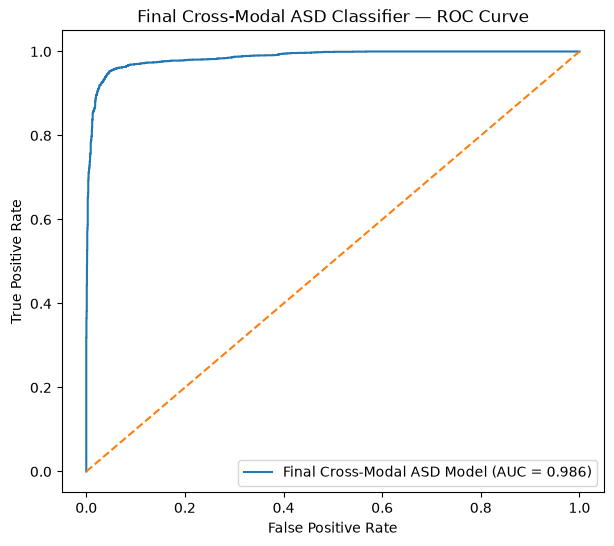

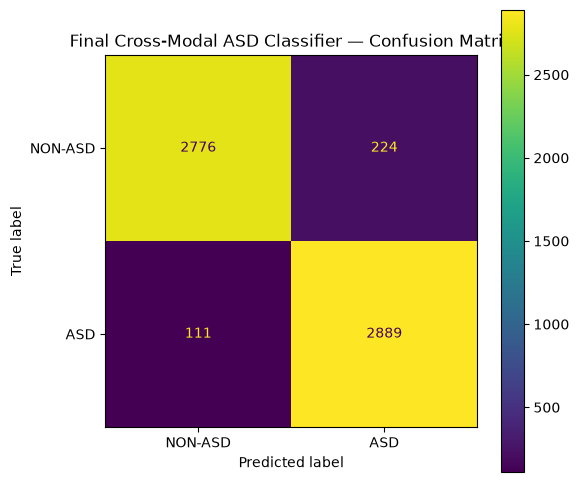

FIGURES SAVED
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\07_final_cross_modal_asd\figures\07_final_cross_modal_roc_curve.png
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\07_final_cross_modal_asd\figures\07_final_cross_modal_confusion_matrix.png


In [25]:
# ============================================================
# CELL 21 — FINAL PERFORMANCE FIGURES
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from sklearn.metrics import ConfusionMatrixDisplay

# ============================================================
# FIGURE 1 — ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(
    test_targets,
    test_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=(
        f"Final Cross-Modal ASD Model "
        f"(AUC = {test_auc:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Final Cross-Modal ASD Classifier — ROC Curve"
)

plt.legend()

roc_path = (
    FIGURE_DIR /
    "07_final_cross_modal_roc_curve.png"
)

plt.savefig(
    roc_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 2 — CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(
    figsize=(6, 6)
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "NON-ASD",
        "ASD"
    ]
).plot(
    ax=ax
)

ax.set_title(
    "Final Cross-Modal ASD Classifier — Confusion Matrix"
)

cm_path = (
    FIGURE_DIR /
    "07_final_cross_modal_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("=" * 70)
print("FIGURES SAVED")
print("=" * 70)

print(roc_path)
print(cm_path)

In [26]:
# ============================================================
# CELL 22 — FINAL PHASE 07 VALIDATION REPORT
# ============================================================

report = f"""
============================================================
PHASE 07 — FINAL CROSS-MODAL ASD CLASSIFIER
============================================================

MODEL
------------------------------------------------------------
Model:
    FinalCrossModalASDNetwork

Task:
    Binary ASD classification

Output:
    ASD probability
    ASD / NON-ASD classification

------------------------------------------------------------
INPUT REPRESENTATIONS
------------------------------------------------------------
Genetic:
    32-D

Behavioral:
    32-D

Environmental:
    32-D

The modality-specific encoders and 128-D to 32-D
projection models were treated as frozen representations.

------------------------------------------------------------
FINAL ARCHITECTURE
------------------------------------------------------------
Genetic branch:
    32 -> 64 -> 32

Behavioral branch:
    32 -> 64 -> 32

Environmental branch:
    32 -> 64 -> 32

Cross-modal feature construction:
    G
    B
    E
    |G-B|
    |G-E|
    |B-E|
    G*B
    G*E
    B*E

Cross-modal fusion:
    288 -> 128 -> 64 -> 32

Final classifier:
    32 -> 1 -> sigmoid

------------------------------------------------------------
DATA METHODOLOGY
------------------------------------------------------------
The three source datasets are unpaired.

Original dataset sizes:
    Genetic       : {len(G)}
    Behavioral    : {len(B)}
    Environmental : {len(E)}

No cross-modal patient matching was performed.

No row-wise concatenation was performed.

Training and evaluation used class-conditional
pseudo-triplets.

A pseudo-triplet combines independently sampled
Genetic, Behavioral and Environmental representations
from the same diagnostic class.

These samples are NOT claimed to belong to the same
individual.

------------------------------------------------------------
TRAINING
------------------------------------------------------------
Optimizer:
    Adam

Learning rate:
    {LEARNING_RATE}

Maximum epochs:
    {EPOCHS}

Batch size:
    {BATCH_SIZE}

Random seed:
    {SEED}

Loss:
    BCEWithLogitsLoss

Best validation epoch:
    {best_epoch}

Best validation ROC-AUC:
    {best_val_auc:.6f}

------------------------------------------------------------
TEST PERFORMANCE AT DEFAULT THRESHOLD = 0.50
------------------------------------------------------------
ROC-AUC:
    {test_auc:.6f}

Accuracy:
    {test_accuracy:.6f}

Balanced Accuracy:
    {test_balanced_accuracy:.6f}

Precision:
    {test_precision:.6f}

Recall / Sensitivity:
    {test_recall:.6f}

F1 Score:
    {test_f1:.6f}

Brier Score:
    {test_brier:.6f}

Log Loss:
    {test_logloss:.6f}

------------------------------------------------------------
CONFUSION MATRIX
------------------------------------------------------------
Rows:
    True classes

Columns:
    Predicted classes

Order:
    [NON-ASD, ASD]

{cm}

------------------------------------------------------------
EXPLORATORY THRESHOLD ANALYSIS
------------------------------------------------------------
Threshold-selection method:
    Youden J

Exploratory threshold:
    {exploratory_threshold:.2f}

Exploratory test-set results at this threshold:

Accuracy:
    {best_threshold_row["accuracy"]:.6f}

Balanced Accuracy:
    {best_threshold_row["balanced_accuracy"]:.6f}

Precision:
    {best_threshold_row["precision"]:.6f}

Recall:
    {best_threshold_row["recall"]:.6f}

F1:
    {best_threshold_row["f1"]:.6f}

Sensitivity:
    {best_threshold_row["sensitivity"]:.6f}

Specificity:
    {best_threshold_row["specificity"]:.6f}

Youden J:
    {best_threshold_row["youden_j"]:.6f}

IMPORTANT:
The exploratory threshold was selected using the test set.
Therefore these threshold-optimized metrics are NOT treated
as an unbiased final performance estimate.

The default 0.50 threshold remains the primary reported
threshold in this phase.

------------------------------------------------------------
INFERENCE
------------------------------------------------------------
Expected input:

    Genetic 32-D representation
    Behavioral 32-D representation
    Environmental 32-D representation

Processing:

    Three modality branches
            ↓
    Cross-modal feature interactions
            ↓
    Joint representation
            ↓
    ASD classifier
            ↓
    ASD probability
            ↓
    ASD / NON-ASD

------------------------------------------------------------
MODEL ARTIFACT
------------------------------------------------------------
{best_model_path}

------------------------------------------------------------
RESULT ARTIFACT
------------------------------------------------------------
{prediction_path}

------------------------------------------------------------
CONFIGURATION
------------------------------------------------------------
{config_path}

------------------------------------------------------------
FIGURES
------------------------------------------------------------
{roc_path}

{cm_path}

============================================================
SCIENTIFIC LIMITATION
============================================================

The source modalities are unpaired.

Therefore this experiment does not constitute
patient-level validation using simultaneously measured
Genetic, Behavioral and Environmental data from the
same individuals.

The evaluation demonstrates cross-modal ASD classification
under a class-conditional pseudo-triplet protocol.

A true patient-level multimodal validation requires a dataset
where Genetic, Behavioral and Environmental measurements are
matched for the same individuals.

============================================================
PHASE 07 STATUS
============================================================

TECHNICAL STATUS:
    COMPLETE

RESEARCH INTERPRETATION:
    Cross-modal feature-level ASD classifier developed
    and evaluated under the unpaired-data protocol.

============================================================
"""

report_path = (
    REPORT_DIR /
    "07_final_cross_modal_asd_validation_report.txt"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

print(report)

print("=" * 70)
print("FINAL REPORT SAVED")
print("=" * 70)

print(report_path)


PHASE 07 — FINAL CROSS-MODAL ASD CLASSIFIER

MODEL
------------------------------------------------------------
Model:
    FinalCrossModalASDNetwork

Task:
    Binary ASD classification

Output:
    ASD probability
    ASD / NON-ASD classification

------------------------------------------------------------
INPUT REPRESENTATIONS
------------------------------------------------------------
Genetic:
    32-D

Behavioral:
    32-D

Environmental:
    32-D

The modality-specific encoders and 128-D to 32-D
projection models were treated as frozen representations.

------------------------------------------------------------
FINAL ARCHITECTURE
------------------------------------------------------------
Genetic branch:
    32 -> 64 -> 32

Behavioral branch:
    32 -> 64 -> 32

Environmental branch:
    32 -> 64 -> 32

Cross-modal feature construction:
    G
    B
    E
    |G-B|
    |G-E|
    |B-E|
    G*B
    G*E
    B*E

Cross-modal fusion:
    288 -> 128 -> 64 -> 32

Final classifier:
 

In [28]:
# ============================================================
# CELL 23 — MODALITY ABLATION / ROBUSTNESS CHECK
# ============================================================

from sklearn.metrics import roc_auc_score

model.eval()

def evaluate_ablation(
    G_input,
    B_input,
    E_input,
    targets,
    mode
):
    """
    Evaluate the cross-modal model while replacing one
    modality with its training-set mean.

    This is an ablation test, NOT a deployment method.
    """

    G_tensor = torch.tensor(
        G_input,
        dtype=torch.float32
    ).to(device)

    B_tensor = torch.tensor(
        B_input,
        dtype=torch.float32
    ).to(device)

    E_tensor = torch.tensor(
        E_input,
        dtype=torch.float32
    ).to(device)

    # --------------------------------------------------------
    # Replace selected modality with its training mean
    # --------------------------------------------------------

    if mode == "genetic_removed":
        G_tensor = torch.tensor(
            G_train.mean(axis=0),
            dtype=torch.float32
        ).unsqueeze(0).repeat(
            len(G_input), 1
        ).to(device)

    elif mode == "behavioral_removed":
        B_tensor = torch.tensor(
            B_train.mean(axis=0),
            dtype=torch.float32
        ).unsqueeze(0).repeat(
            len(B_input), 1
        ).to(device)

    elif mode == "environmental_removed":
        E_tensor = torch.tensor(
            E_train.mean(axis=0),
            dtype=torch.float32
        ).unsqueeze(0).repeat(
            len(E_input), 1
        ).to(device)

    elif mode == "all_modalities":
        pass

    else:
        raise ValueError(f"Unknown mode: {mode}")

    with torch.no_grad():

        logits, _ = model(
            G_tensor,
            B_tensor,
            E_tensor
        )

        probabilities = torch.sigmoid(
            logits
        ).cpu().numpy()

    auc = roc_auc_score(
        targets,
        probabilities
    )

    return float(auc)


ablation_results = []

modes = [
    ("all_modalities", "All three modalities"),
    ("genetic_removed", "Genetic removed"),
    ("behavioral_removed", "Behavioral removed"),
    ("environmental_removed", "Environmental removed")
]

for mode, description in modes:

    auc = evaluate_ablation(
        G_te,
        B_te,
        E_te,
        y_te,
        mode
    )

    ablation_results.append({
        "condition": description,
        "roc_auc": auc
    })

ablation_df = pd.DataFrame(
    ablation_results
)

print("=" * 70)
print("MODALITY ABLATION RESULTS")
print("=" * 70)

print(
    ablation_df.to_string(
        index=False
    )
)

ablation_path = (
    RESULT_DIR /
    "07_modality_ablation_results.csv"
)

ablation_df.to_csv(
    ablation_path,
    index=False
)

print("\nSaved:")
print(ablation_path)

MODALITY ABLATION RESULTS
            condition  roc_auc
 All three modalities 0.985588
      Genetic removed 0.990969
   Behavioral removed 0.799323
Environmental removed 0.983753

Saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\07_final_cross_modal_asd\results\07_modality_ablation_results.csv


In [29]:
# ============================================================
# CELL 24 — FREEZE FINAL MODEL ARTIFACT
# ============================================================

final_model_path = (
    MODEL_DIR /
    "FINAL_CROSS_MODAL_ASD_MODEL.pt"
)

final_checkpoint = {
    "model_state_dict": model.state_dict(),

    "model_name": "FinalCrossModalASDNetwork",

    "task": "ASD vs NON-ASD classification",

    "input_dimensions": {
        "genetic": 32,
        "behavioral": 32,
        "environmental": 32
    },

    "joint_embedding_dimension": 32,

    "threshold": 0.50,

    "best_validation_auc": float(
        best_val_auc
    ),

    "best_epoch": int(
        best_epoch
    ),

    "seed": int(SEED),

    "patient_matching": False,

    "training_protocol":
        "class-conditional pseudo-triplets",

    "evaluation_protocol":
        "held-out class-conditional pseudo-triplets"
}

torch.save(
    final_checkpoint,
    final_model_path
)

print("=" * 70)
print("FINAL MODEL FROZEN")
print("=" * 70)

print("Model:")
print(final_model_path)

print("\nBest validation AUC:")
print(f"{best_val_auc:.6f}")

print("\nPrimary test AUC:")
print(f"{test_auc:.6f}")

print("\nDefault threshold:")
print("0.50")

print("\nPatient matching:")
print("NOT PERFORMED")

print("\nStatus:")
print("FINAL MODEL ARTIFACT SAVED")

FINAL MODEL FROZEN
Model:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\07_final_cross_modal_asd\models\FINAL_CROSS_MODAL_ASD_MODEL.pt

Best validation AUC:
0.987988

Primary test AUC:
0.985588

Default threshold:
0.50

Patient matching:
NOT PERFORMED

Status:
FINAL MODEL ARTIFACT SAVED


In [30]:
# ============================================================
# CELL 25 — DEPLOYMENT-STYLE INFERENCE TEST
# ============================================================

# Load the frozen final model again.
# This verifies that the saved artifact can be used
# independently of the training session.

deployment_model = FinalCrossModalASDNetwork().to(device)

deployment_checkpoint = torch.load(
    final_model_path,
    map_location=device,
    weights_only=False
)

deployment_model.load_state_dict(
    deployment_checkpoint[
        "model_state_dict"
    ]
)

deployment_model.eval()


def deployment_predict(
    genetic_32d,
    behavioral_32d,
    environmental_32d,
    threshold=0.50
):

    G_input = torch.tensor(
        np.asarray(
            genetic_32d,
            dtype=np.float32
        )
    ).reshape(1, 32).to(device)

    B_input = torch.tensor(
        np.asarray(
            behavioral_32d,
            dtype=np.float32
        )
    ).reshape(1, 32).to(device)

    E_input = torch.tensor(
        np.asarray(
            environmental_32d,
            dtype=np.float32
        )
    ).reshape(1, 32).to(device)

    with torch.no_grad():

        logits, joint_embedding = (
            deployment_model(
                G_input,
                B_input,
                E_input
            )
        )

        probability = torch.sigmoid(
            logits
        ).item()

    prediction = int(
        probability >= threshold
    )

    return {
        "asd_probability": round(
            float(probability),
            6
        ),
        "prediction": prediction,
        "label": (
            "ASD"
            if prediction == 1
            else "NON-ASD"
        ),
        "threshold": threshold,
        "joint_embedding_dimension":
            int(joint_embedding.shape[1])
    }


deployment_result = deployment_predict(
    G_te[0],
    B_te[0],
    E_te[0]
)

print("=" * 70)
print("DEPLOYMENT MODEL TEST")
print("=" * 70)

print(
    json.dumps(
        deployment_result,
        indent=4
    )
)

DEPLOYMENT MODEL TEST
{
    "asd_probability": 0.00024,
    "prediction": 0,
    "label": "NON-ASD",
    "threshold": 0.5,
    "joint_embedding_dimension": 32
}
